In [53]:
import pandas as pd

In [54]:
csv = "outputs/matrix_shiptype_x_defcode_2018_2021.csv"
csv = pd.read_csv(csv)

In [55]:
csv.head

<bound method NDFrame.head of                      ship_type  01101  01102  01103  01104  01105  01106  \
0                   NLS tanker      0      0      0      0      0      0   
1          Combination carrier      0      0      0      0      0      0   
2                   Oil tanker     22     15      0     10      0      4   
3   Oil tanker/Chemical tanker      8      5      0      2      0      0   
4             Commercial yacht      5      1      0     19      0      1   
5       Gas Carrier/NLS tanker      0      0      0      0      0      0   
6              Chemical tanker     24     19      0     10      2      9   
7                 Bulk carrier    110     27      0     18      1     17   
8                    Container     53     18      0     10      0      5   
9                  Ro-Ro cargo     30      8      1     10      3      5   
10  General cargo/multipurpose    302     85      0     93     47     73   
11          Refrigerated cargo     10      2      0      2

In [56]:
ship_types = "shipType.xls"
ship_types = pd.DataFrame(pd.read_excel(ship_types))
print(ship_types[0:])




    Code                                      Description Abbreviation  \
0    310                                    Tankship + cc           CC   
1    311                                       NLS tanker          NLS   
2    312                              Combination carrier         COMB   
3    313                                       Oil tanker          OIL   
4    314                      Oil tanker/Chemical tanker       OILCHEM   
5    315                                   Fishing vessel         FISH   
6    316                      Warship and naval auxiliary      WARSHIP   
7    317                 Wooden ship of a primitive build         WOOD   
8    318  Government ship used for non-commercial purpose       GOVERN   
9    319              Pleasure yacht not engaged in trade        YACHT   
10   320                                      Gas carrier          GAS   
11   321                           Oil tanker/NLS tanker        OILNLS   
12   322                          Oil 

In [57]:
print(ship_types[23:])

    Code                 Description Abbreviation Effect Date Expiry Date  \
23   355                 Ro-Ro cargo        ROROC  01/01/1982         NaN   
24   360  General cargo/multipurpose          GEN  01/01/1982         NaN   
25   361          Refrigerated cargo          RCV  01/01/1982         NaN   
26   367           Livestock carrier         LIVE  01/01/1982         NaN   
27   370        Ro-Ro passenger ship        ROROP  01/01/1982         NaN   
28   371              Passenger ship          PAX  01/01/1982         NaN   
29   372                 Ice breaker          ICE  01/01/1982  01/01/2000   
30   373                Fish factory         FACT  01/01/1982         NaN   
31   374               Research ship     RESEARCH  01/01/1982  01/01/2000   
32   375                  Heavy load         HEAV  01/01/1982         NaN   
33   376             Offshore supply          OSV  01/01/1982         NaN   
34   377                Standby ship         STBY  01/01/1982  01/01/2000   

In [58]:
ship_types.to_csv('ship_types_.csv')

After data preparation/ cleaning

In [59]:
matrix = pd.read_csv('matrix.csv')


Πλήρης πίνακας τύπων πλοίων με defeciencies codes ανά ship type

Δεν συμπεριλαμβάνεται το "other", καθώς δεν βρήκαμε σαφή ορισμό στο paper. Διατηρήσαμε τα υπόλοιπα.

In [60]:
matrix

,ship_type,01101,01102,01103,01104,01105,01106,01107,01108,01110,...,18428,18429,18430,18431,18432,18499,99101,99102,99103,Other
0,NLS tanker,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,2
1,Combination carrier,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,Oil tanker,22,15,0,10,0,4,7,3,0,...,2,3,0,0,14,21,20,8,0,123
3,Oil tanker/Chemical tanker,8,5,0,2,0,0,5,2,0,...,2,0,0,0,16,8,9,2,1,25
4,Commercial yacht,5,1,0,19,0,1,0,7,0,...,0,0,0,0,0,1,3,1,0,8
5,Gas Carrier/NLS tanker,0,0,0,0,0,0,0,0,0,...,0,0,0,0,2,0,0,0,1,0
6,Chemical tanker,24,19,0,10,2,9,10,10,0,...,3,3,0,1,7,37,27,8,1,76
7,Bulk carrier,110,27,0,18,1,17,37,19,1,...,39,14,4,0,50,234,172,34,8,336
8,Container,53,18,0,10,0,5,12,9,0,...,8,4,0,0,26,116,40,27,2,123
9,Ro-Ro cargo,30,8,1,10,3,5,8,6,0,...,0,2,0,2,22,32,8,6,1,82


In [61]:
matrix.shape

(20, 497)

In [62]:
sum_matrix0 = matrix
sum_matrix0 = sum_matrix0.sum(axis = 'columns', numeric_only= True)



In [63]:
sum_matrix0

0       146
1        36
2      5911
3      1847
4       958
5        30
6      7122
7     32166
8     10809
9      4255
10    58366
11     1716
12     3951
13     1457
14      254
15     2498
16      706
17      521
18     1781
19     3264
dtype: int64

In [64]:
sum_matrix0 = sum_matrix0.reset_index()

sum_matrix0

,index,0
0,0,146
1,1,36
2,2,5911
3,3,1847
4,4,958
5,5,30
6,6,7122
7,7,32166
8,8,10809
9,9,4255


In [65]:
matrix_bar = sum_matrix0
matrix_bar.columns = ["ship_code", "def_code"]


In [66]:
matrix_bar

,ship_code,def_code
0,0,146
1,1,36
2,2,5911
3,3,1847
4,4,958
5,5,30
6,6,7122
7,7,32166
8,8,10809
9,9,4255


In [67]:
X = matrix_bar["ship_code"]
Y = matrix_bar["def_code"]

Κατασκευή Bar Plot για αρχική προβολή συνόλου Deficiencies ανά τύπο

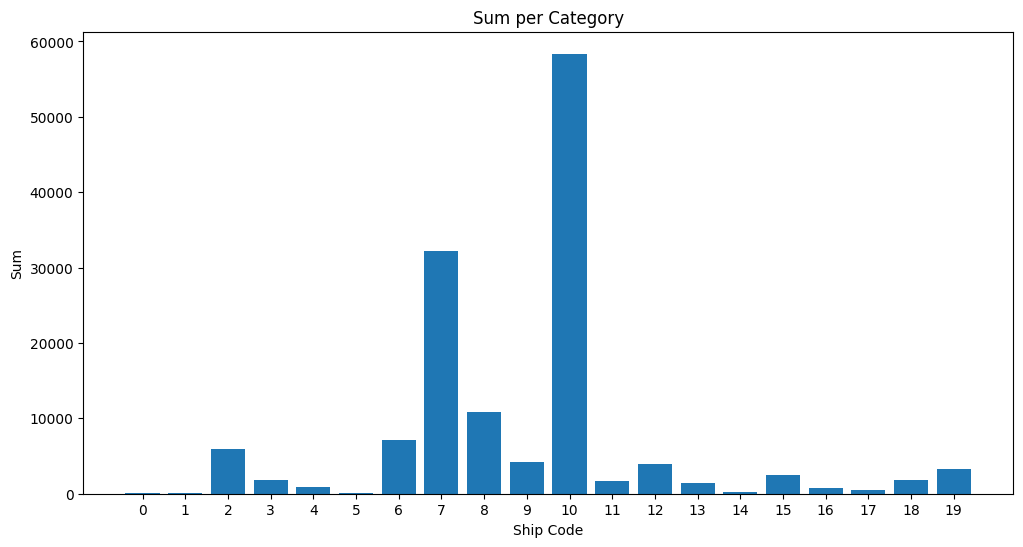

In [68]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
plt.bar(matrix_bar["ship_code"], matrix_bar["def_code"])
plt.xlabel("Ship Code")
plt.ylabel("Sum")
plt.title("Sum per Category")
plt.xticks(range(20))
plt.show()


In [69]:
import numpy as np
from scipy.stats import rankdata


Μετατροπή σε numpy array για ταχύτητα.


In [70]:
data = matrix.values

In [71]:
data

array([['NLS tanker', 0, 0, ..., 0, 0, 2],
       ['Combination carrier', 0, 0, ..., 0, 0, 0],
       ['Oil tanker', 22, 15, ..., 8, 0, 123],
       ...,
       ['High speed passenger craft', 0, 0, ..., 1, 1, 4],
       ['Tug', 3, 1, ..., 0, 0, 6],
       ['Other special activities', 21, 7, ..., 4, 0, 30]], dtype=object)

Alternatives & Criteria

In [72]:
A = matrix["ship_type"]
E = matrix.drop(columns = "ship_type")

E = E.values

A

0                     NLS tanker
1            Combination carrier
2                     Oil tanker
3     Oil tanker/Chemical tanker
4               Commercial yacht
5         Gas Carrier/NLS tanker
6                Chemical tanker
7                   Bulk carrier
8                      Container
9                    Ro-Ro cargo
10    General cargo/multipurpose
11            Refrigerated cargo
12          Ro-Ro passenger ship
13                Passenger ship
14                    Heavy load
15               Offshore supply
16          Special purpose ship
17    High speed passenger craft
18                           Tug
19      Other special activities
Name: ship_type, dtype: object

In [73]:
E

array([[  0,   0,   0, ...,   0,   0,   2],
       [  0,   0,   0, ...,   0,   0,   0],
       [ 22,  15,   0, ...,   8,   0, 123],
       ...,
       [  0,   0,   0, ...,   1,   1,   4],
       [  3,   1,   0, ...,   0,   0,   6],
       [ 21,   7,   2, ...,   4,   0,  30]])

#1: GRA

Χρήση Sklearn για MinMAxScaler

In [74]:
from sklearn.preprocessing import MinMaxScaler

normalization = MinMaxScaler()

MMScaled = normalization.fit_transform(E)

print(MMScaled)

[[0.         0.         0.         ... 0.         0.         0.00212766]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.07284768 0.17647059 0.         ... 0.08602151 0.         0.13085106]
 ...
 [0.         0.         0.         ... 0.01075269 0.125      0.00425532]
 [0.00993377 0.01176471 0.         ... 0.         0.         0.00638298]
 [0.06953642 0.08235294 0.06666667 ... 0.04301075 0.         0.03191489]]


Reference Sequence

In [75]:
ref_seq = np.max(MMScaled, axis=0)

print(ref_seq)

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.

In [76]:
# Absolute Difference
delta = np.abs(ref_seq - MMScaled)

print(delta)

[[1.         1.         1.         ... 1.         1.         0.99787234]
 [1.         1.         1.         ... 1.         1.         1.        ]
 [0.92715232 0.82352941 1.         ... 0.91397849 1.         0.86914894]
 ...
 [1.         1.         1.         ... 0.98924731 0.875      0.99574468]
 [0.99006623 0.98823529 1.         ... 1.         1.         0.99361702]
 [0.93046358 0.91764706 0.93333333 ... 0.95698925 1.         0.96808511]]


Συντελεστής συσχέτισης


In [77]:
xi = 0.5 

delta_min = np.min(delta)
delta_max = np.max(delta)

print(delta_min)
print(delta_max)

0.0
1.0


In [78]:
rel_coef = (delta_min +xi * delta_max)/ (delta + xi * delta_max)

print(rel_coef)

[[0.33333333 0.33333333 0.33333333 ... 0.33333333 0.33333333 0.33380682]
 [0.33333333 0.33333333 0.33333333 ... 0.33333333 0.33333333 0.33333333]
 [0.35034803 0.37777778 0.33333333 ... 0.35361217 0.33333333 0.36519037]
 ...
 [0.33333333 0.33333333 0.33333333 ... 0.33574007 0.36363636 0.33428165]
 [0.33555556 0.33596838 0.33333333 ... 0.33333333 0.33333333 0.33475783]
 [0.34953704 0.3526971  0.34883721 ... 0.34317343 0.33333333 0.34057971]]


Υπολογισμός Μ.Ο ανά γραμμή

In [79]:
grey_grades = np.mean(rel_coef, axis = 1)
print(grey_grades)

[0.3367685  0.33486348 0.37356627 0.34558934 0.33884845 0.33489694
 0.39760568 0.57398613 0.40306619 0.35224353 0.8180413  0.34318122
 0.3737282  0.34573438 0.33551848 0.35243356 0.33994368 0.33935017
 0.34330417 0.35135142]


In [80]:
GRA_results = pd.DataFrame({
    'Ship type': A,
    'GRA Grades': grey_grades
})

In [81]:
GRA_results

,Ship type,GRA Grades
0,NLS tanker,0.336768
1,Combination carrier,0.334863
2,Oil tanker,0.373566
3,Oil tanker/Chemical tanker,0.345589
4,Commercial yacht,0.338848
5,Gas Carrier/NLS tanker,0.334897
6,Chemical tanker,0.397606
7,Bulk carrier,0.573986
8,Container,0.403066
9,Ro-Ro cargo,0.352244


In [82]:
finalGRA = GRA_results.sort_values(by = 'GRA Grades', ascending= False)

finalGRA

,Ship type,GRA Grades
10,General cargo/multipurpose,0.818041
7,Bulk carrier,0.573986
8,Container,0.403066
6,Chemical tanker,0.397606
12,Ro-Ro passenger ship,0.373728
2,Oil tanker,0.373566
15,Offshore supply,0.352434
9,Ro-Ro cargo,0.352244
19,Other special activities,0.351351
13,Passenger ship,0.345734


#2: TOPSIS

In [83]:
topsisdata = np.array(E, dtype= float)
print(topsisdata)

[[  0.   0.   0. ...   0.   0.   2.]
 [  0.   0.   0. ...   0.   0.   0.]
 [ 22.  15.   0. ...   8.   0. 123.]
 ...
 [  0.   0.   0. ...   1.   1.   4.]
 [  3.   1.   0. ...   0.   0.   6.]
 [ 21.   7.   2. ...   4.   0.  30.]]


In [84]:

# E: numpy array (m ship types x n deficiency codes)
E = np.array(E, dtype=float)

# Υπολογισμός divisor για κάθε στήλη (criterion)
divisors = np.sqrt(np.sum(E**2, axis=0))
divisors[divisors == 0] = 1

# Normalized decision matrix
R = E / divisors
R


array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.00195511],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.06621312, 0.15691544, 0.        , ..., 0.07628394, 0.        ,
        0.12023937],
       ...,
       [0.        , 0.        , 0.        , ..., 0.00953549, 0.08737041,
        0.00391022],
       [0.00902906, 0.01046103, 0.        , ..., 0.        , 0.        ,
        0.00586534],
       [0.06320343, 0.07322721, 0.05536365, ..., 0.03814197, 0.        ,
        0.02932668]])

In [85]:
R

array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.00195511],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.06621312, 0.15691544, 0.        , ..., 0.07628394, 0.        ,
        0.12023937],
       ...,
       [0.        , 0.        , 0.        , ..., 0.00953549, 0.08737041,
        0.00391022],
       [0.00902906, 0.01046103, 0.        , ..., 0.        , 0.        ,
        0.00586534],
       [0.06320343, 0.07322721, 0.05536365, ..., 0.03814197, 0.        ,
        0.02932668]])

In [86]:
print(R.shape)          
print(np.min(R), np.max(R))


(20, 496)
0.0 1.0


In [87]:
#ideal best
best = np.max(R, axis = 0)
best.shape

(496,)

In [88]:
#ideal worst
worst = np.min(R, axis = 0)
worst.shape

(496,)

In [89]:
dif_best = R - best
dif_worst = R - worst

best2 = np.sum(dif_best ** 2, axis = 1)
worst2 = np.sum(dif_worst ** 2, axis =1)

sbest = np.sqrt(best2)
sworst = np.sqrt(worst2)

In [90]:
print(sbest)
print(sworst)

[19.13633281 19.18023619 17.61584475 18.62563131 18.89379352 19.17885205
 16.95835856 12.56780241 16.47109883 18.16238662  9.11557129 18.76234351
 17.95011105 18.71138406 19.13125839 18.44539815 18.98398327 18.99250963
 18.71242929 18.2842454 ]
[ 0.62597379  0.14222043  3.56343994  1.6501818   0.85228785  0.13407099
  5.40760326 10.80424161  5.18045809  2.01260766 16.18527273  1.40883915
  4.11419728  1.89171395  0.20363063  2.52176935  1.18896548  1.50390971
  1.37561902  2.26482681]


In [91]:
closest_coef = sworst/ (sbest + sworst)
closest_coef

array([0.03167514, 0.00736037, 0.16825119, 0.08138671, 0.04316238,
       0.00694204, 0.24177826, 0.462272  , 0.23926492, 0.09975753,
       0.63971276, 0.06984415, 0.18646391, 0.09181697, 0.01053177,
       0.12027229, 0.05893861, 0.07337427, 0.06847948, 0.11021553])

In [92]:
TOPSIS = pd.DataFrame({
    'Ship type': A,
    'S Best': sbest,
    'S worst': sworst,
    'Closest Coefficient': closest_coef
})

In [93]:
TOPSIS = TOPSIS.sort_values(by = 'Closest Coefficient', ascending= False)
TOPSIS

,Ship type,S Best,S worst,Closest Coefficient
10,General cargo/multipurpose,9.115571,16.185273,0.639713
7,Bulk carrier,12.567802,10.804242,0.462272
6,Chemical tanker,16.958359,5.407603,0.241778
8,Container,16.471099,5.180458,0.239265
12,Ro-Ro passenger ship,17.950111,4.114197,0.186464
2,Oil tanker,17.615845,3.563440,0.168251
15,Offshore supply,18.445398,2.521769,0.120272
19,Other special activities,18.284245,2.264827,0.110216
9,Ro-Ro cargo,18.162387,2.012608,0.099758
13,Passenger ship,18.711384,1.891714,0.091817


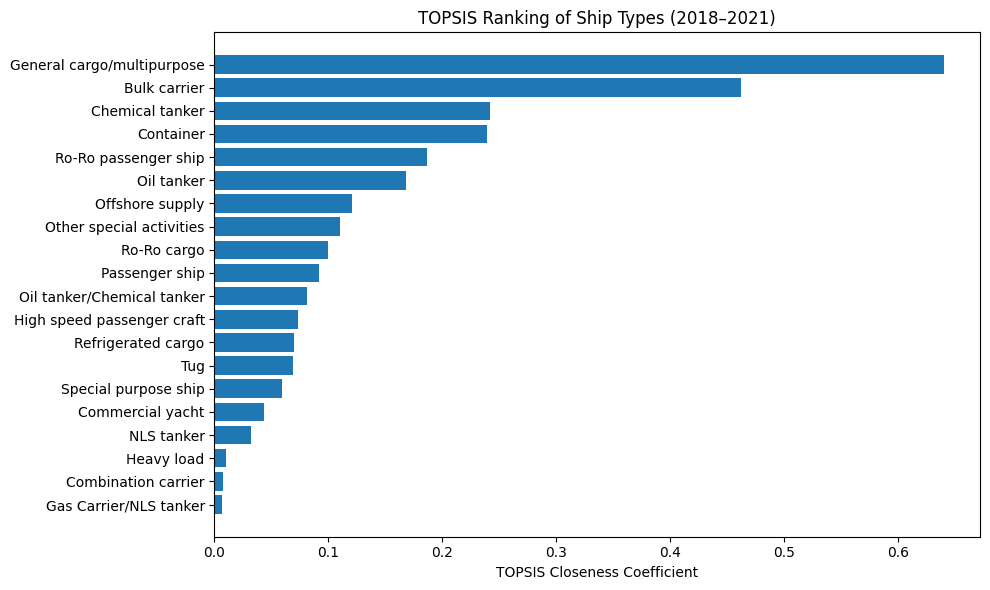

In [143]:
plt.figure(figsize=(10,6))
plt.barh(
    TOPSIS['Ship type'],
    TOPSIS['Closest Coefficient']
)
plt.xlabel('TOPSIS Closeness Coefficient')
plt.title('TOPSIS Ranking of Ship Types (2018–2021)')
plt.gca().invert_yaxis()  # ο καλύτερος επάνω
plt.tight_layout()
plt.show()

In [145]:
compare = pd.merge(
    GRA_results[['Ship type', 'GRA Grades']],
    TOPSIS[['Ship type', 'Closest Coefficient']],
    on='Ship type'
)

compare['GRA Rank'] = compare['GRA Grades'].rank(ascending=False)
compare['TOPSIS Rank'] = compare['Closest Coefficient'].rank(ascending=False)

compare.sort_values('TOPSIS Rank')



,Ship type,GRA Grades,Closest Coefficient,GRA Rank,TOPSIS Rank
10,General cargo/multipurpose,0.818041,0.639713,1.0,1.0
7,Bulk carrier,0.573986,0.462272,2.0,2.0
6,Chemical tanker,0.397606,0.241778,4.0,3.0
8,Container,0.403066,0.239265,3.0,4.0
12,Ro-Ro passenger ship,0.373728,0.186464,5.0,5.0
2,Oil tanker,0.373566,0.168251,6.0,6.0
15,Offshore supply,0.352434,0.120272,7.0,7.0
19,Other special activities,0.351351,0.110216,9.0,8.0
9,Ro-Ro cargo,0.352244,0.099758,8.0,9.0
13,Passenger ship,0.345734,0.091817,10.0,10.0


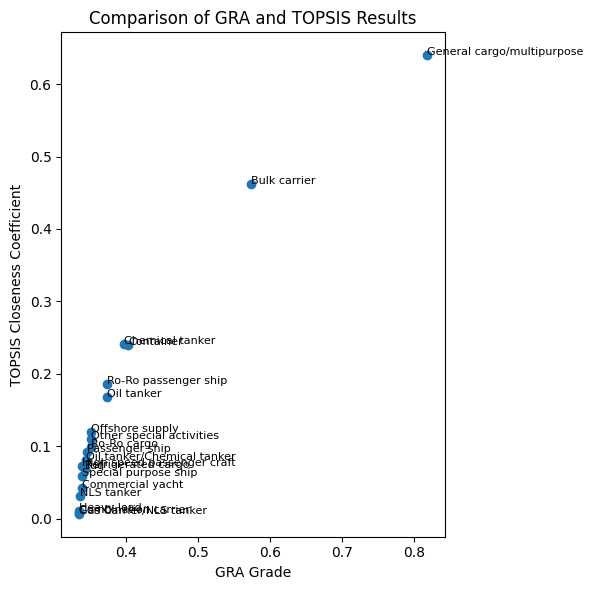

In [146]:
plt.figure(figsize=(6,6))
plt.scatter(compare['GRA Grades'], compare['Closest Coefficient'])

for _, row in compare.iterrows():
    plt.text(row['GRA Grades'], row['Closest Coefficient'], row['Ship type'], fontsize=8)

plt.xlabel('GRA Grade')
plt.ylabel('TOPSIS Closeness Coefficient')
plt.title('Comparison of GRA and TOPSIS Results')
plt.tight_layout()
plt.show()


#3: Three Sigma Rule

In [94]:
sum = np.sum(E, axis = 0)
sum

array([6.310e+02, 2.020e+02, 5.300e+01, 2.000e+02, 6.800e+01, 1.490e+02,
       1.960e+02, 1.750e+02, 3.000e+00, 1.000e+00, 4.060e+02, 1.000e+00,
       2.100e+01, 7.000e+00, 3.110e+02, 4.000e+00, 1.640e+02, 1.000e+00,
       1.333e+03, 3.020e+02, 2.090e+02, 3.200e+01, 1.300e+01, 9.000e+00,
       1.000e+00, 1.640e+02, 1.500e+02, 2.300e+01, 3.000e+00, 6.000e+00,
       2.770e+02, 2.190e+02, 9.000e+01, 3.820e+02, 3.060e+02, 3.930e+02,
       3.470e+02, 1.200e+02, 2.900e+01, 2.000e+01, 2.000e+00, 1.400e+01,
       2.090e+02, 6.000e+00, 1.300e+01, 9.000e+00, 9.900e+01, 6.890e+02,
       1.590e+02, 1.000e+00, 4.660e+02, 1.400e+01, 1.974e+03, 2.200e+01,
       2.300e+01, 8.900e+01, 5.300e+01, 4.300e+01, 1.700e+01, 6.000e+00,
       3.110e+02, 4.550e+02, 2.120e+02, 1.100e+03, 2.100e+02, 4.990e+02,
       2.700e+01, 1.400e+01, 2.800e+01, 7.490e+02, 2.016e+03, 1.050e+02,
       2.400e+01, 1.100e+01, 1.000e+01, 8.340e+02, 7.400e+01, 2.530e+02,
       3.260e+02, 9.000e+00, 1.660e+02, 5.000e+00, 

In [95]:
mean = np.mean(sum)
mean

np.float64(277.81048387096774)

In [96]:
dif = np.sum((sum - mean)**2)
dif

np.float64(123595594.18548387)

In [97]:
sigma = dif/495
sigma = np.sqrt(sigma)
sigma

np.float64(499.68797169992354)

In [98]:
t3 = mean + (3 * sigma)
t4 = mean + (4 * sigma)
t5 = mean + (5 * sigma)
t6 = mean + (6 * sigma)

print(t3,t4,t5,t6)

1776.8743989707384 2276.562370670662 2776.2503423705857 3275.938314070509


In [99]:
sum

array([6.310e+02, 2.020e+02, 5.300e+01, 2.000e+02, 6.800e+01, 1.490e+02,
       1.960e+02, 1.750e+02, 3.000e+00, 1.000e+00, 4.060e+02, 1.000e+00,
       2.100e+01, 7.000e+00, 3.110e+02, 4.000e+00, 1.640e+02, 1.000e+00,
       1.333e+03, 3.020e+02, 2.090e+02, 3.200e+01, 1.300e+01, 9.000e+00,
       1.000e+00, 1.640e+02, 1.500e+02, 2.300e+01, 3.000e+00, 6.000e+00,
       2.770e+02, 2.190e+02, 9.000e+01, 3.820e+02, 3.060e+02, 3.930e+02,
       3.470e+02, 1.200e+02, 2.900e+01, 2.000e+01, 2.000e+00, 1.400e+01,
       2.090e+02, 6.000e+00, 1.300e+01, 9.000e+00, 9.900e+01, 6.890e+02,
       1.590e+02, 1.000e+00, 4.660e+02, 1.400e+01, 1.974e+03, 2.200e+01,
       2.300e+01, 8.900e+01, 5.300e+01, 4.300e+01, 1.700e+01, 6.000e+00,
       3.110e+02, 4.550e+02, 2.120e+02, 1.100e+03, 2.100e+02, 4.990e+02,
       2.700e+01, 1.400e+01, 2.800e+01, 7.490e+02, 2.016e+03, 1.050e+02,
       2.400e+01, 1.100e+01, 1.000e+01, 8.340e+02, 7.400e+01, 2.530e+02,
       3.260e+02, 9.000e+00, 1.660e+02, 5.000e+00, 

In [100]:
matrix

,ship_type,01101,01102,01103,01104,01105,01106,01107,01108,01110,...,18428,18429,18430,18431,18432,18499,99101,99102,99103,Other
0,NLS tanker,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,2
1,Combination carrier,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,Oil tanker,22,15,0,10,0,4,7,3,0,...,2,3,0,0,14,21,20,8,0,123
3,Oil tanker/Chemical tanker,8,5,0,2,0,0,5,2,0,...,2,0,0,0,16,8,9,2,1,25
4,Commercial yacht,5,1,0,19,0,1,0,7,0,...,0,0,0,0,0,1,3,1,0,8
5,Gas Carrier/NLS tanker,0,0,0,0,0,0,0,0,0,...,0,0,0,0,2,0,0,0,1,0
6,Chemical tanker,24,19,0,10,2,9,10,10,0,...,3,3,0,1,7,37,27,8,1,76
7,Bulk carrier,110,27,0,18,1,17,37,19,1,...,39,14,4,0,50,234,172,34,8,336
8,Container,53,18,0,10,0,5,12,9,0,...,8,4,0,0,26,116,40,27,2,123
9,Ro-Ro cargo,30,8,1,10,3,5,8,6,0,...,0,2,0,2,22,32,8,6,1,82


In [101]:
codes = matrix.columns[1:].astype(str)
codes

Index(['01101', '01102', '01103', '01104', '01105', '01106', '01107', '01108',
       '01110', '01112',
       ...
       '18428', '18429', '18430', '18431', '18432', '18499', '99101', '99102',
       '99103', 'Other'],
      dtype='object', length=496)

In [102]:
sumdf = pd.DataFrame({'Codes':codes,'Sums': sum})
sumdf

,Codes,Sums
0,01101,631.0
1,01102,202.0
2,01103,53.0
3,01104,200.0
4,01105,68.0
...,...,...
491,18499,721.0
492,99101,531.0
493,99102,208.0
494,99103,27.0


In [103]:
sumdf_3sigma = sumdf[sumdf["Sums"] > t3]
sumdf_4sigma = sumdf[sumdf["Sums"] > t4]
sumdf_5sigma = sumdf[sumdf["Sums"] > t5]
sumdf_6sigma = sumdf[sumdf["Sums"] > t6]


In [104]:
sumdf_3sigma.sort_values(by="Sums", ascending=False)

,Codes,Sums
420,15150,6509.0
197,07105,3832.0
278,10116,2131.0
70,01315,2016.0
52,01220,1974.0
495,Other,1902.0
273,10111,1850.0


In [105]:
sumdf_4sigma.sort_values(by="Sums", ascending=False)

,Codes,Sums
420,15150,6509.0
197,07105,3832.0


In [106]:
sumdf_5sigma.sort_values(by="Sums", ascending=False)

,Codes,Sums
420,15150,6509.0
197,07105,3832.0


In [107]:
sumdf_6sigma.sort_values(by="Sums", ascending=False)

,Codes,Sums
420,15150,6509.0
197,07105,3832.0


In [135]:
final = matrix[["15150","07105","10116","01315","01220"]]

In [136]:
final 

,15150,07105,10116,01315,01220
0,6,5,1,0,1
1,1,1,1,0,0
2,275,249,64,62,118
3,116,48,15,15,65
4,14,3,35,38,5
5,1,0,0,2,1
6,340,240,71,63,133
7,1656,901,312,283,556
8,569,325,87,110,144
9,237,138,41,50,91


In [137]:
final["Ship type"] = A.values
final


/var/folders/s0/k6p2569n6w1br5pz86sgwm400000gn/T/ipykernel_2628/3316565445.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final["Ship type"] = A.values


,15150,07105,10116,01315,01220,Ship type
0,6,5,1,0,1,NLS tanker
1,1,1,1,0,0,Combination carrier
2,275,249,64,62,118,Oil tanker
3,116,48,15,15,65,Oil tanker/Chemical tanker
4,14,3,35,38,5,Commercial yacht
5,1,0,0,2,1,Gas Carrier/NLS tanker
6,340,240,71,63,133,Chemical tanker
7,1656,901,312,283,556,Bulk carrier
8,569,325,87,110,144,Container
9,237,138,41,50,91,Ro-Ro cargo


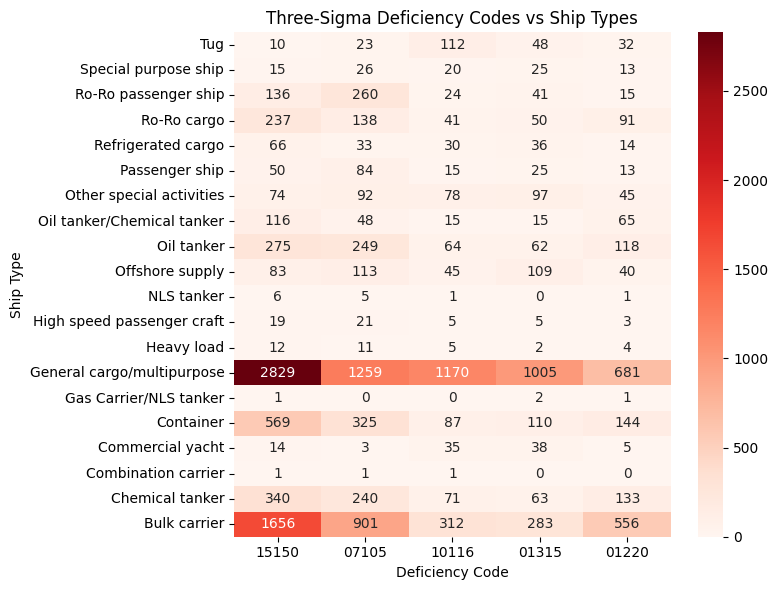

In [147]:
import seaborn as sns

plt.figure(figsize=(8,6))
sns.heatmap(
    final.set_index('Ship type'),
    annot=True,
    fmt='d',
    cmap='Reds'
)

plt.title('Three-Sigma Deficiency Codes vs Ship Types')
plt.xlabel('Deficiency Code')
plt.ylabel('Ship Type')
plt.tight_layout()
plt.show()
